## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('.//ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

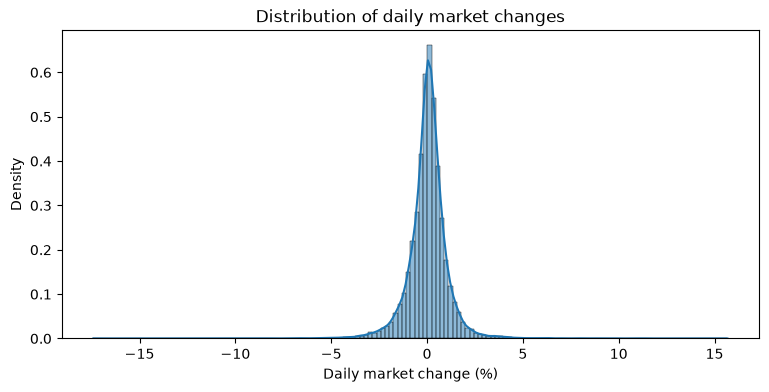

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

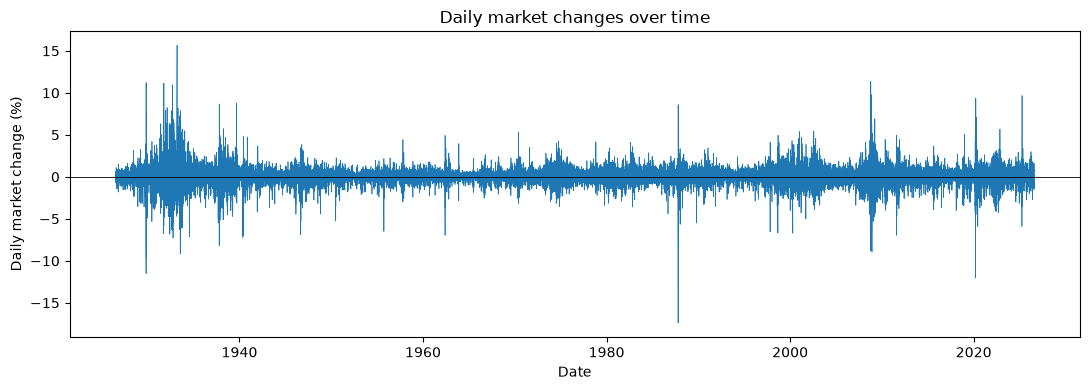

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
    - bin5_t
        - Large loss    2759
        - Small loss    7452
        - Near zero     3441
        - Small gain    9785
        - Large gain    2859
    - The most common is the small gain at 9785
    - The least common is the Large loss with 2759
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
    - large loss to small loss
    - small loss to small gain
    - near zero to small gain
    - small gain to small gain
    - large gain to small gain
    - The most likely transition overall is to a small gain and the second most likely is to a small loss
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
    - None of the rows are perfectly uniform at .2, but Large loss is the closest to it.
    - Overall with the differences in rows are minimal so it seems difficult to predict properly which state comes next.
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 
    - If the current state is a loss then the expected returns are negative, but once it turns near zero and above the returns are expected to be positive. 
    - Min and Max
        - Large Loss - (−17.41,	11.22)
        - Small Loss - (−11.23,	11.36)
        - Near Zero - (−8.19, 5.49)
        - Small Gain - (−8.25, 8.67)
        - Large Gain - (−12.00, 15.67)
        - Large loss and gain have the largest spread. Narrowest is Near Zero and Small Gain
    - STD
        - The standard deviation is largest for Large loss and Large gain.
    - The volatility is almost the same for near zero gain and small gain. 

In [6]:
labels5 = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['bin5_t'] = pd.cut(df['market_return_pct'],
                      bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf],
                      labels=labels5, right=True)
df['bin5_tp1'] = df['bin5_t'].shift(-1)
df['ret_tp1'] = df['market_return_pct'].shift(-1)
p5 = df.dropna(subset=['bin5_tp1'])

# bin counts
print(df['bin5_t'].value_counts().reindex(labels5), "\n")

# joint, marginals, conditional
joint5 = pd.crosstab(p5['bin5_t'], p5['bin5_tp1'], normalize='all')
marg_t5 = joint5.sum(axis=1)
marg_tp1_5 = joint5.sum(axis=0)
cond5 = joint5.div(marg_t5, axis=0)
print("Joint PMF\n", joint5.round(4), "\n")
print("Marginals\n", marg_t5.round(4), "\n", marg_tp1_5.round(4), "\n")
print("Conditional PMF\n", cond5.round(3), "\n")

# two most likely next states for each current state
for s in labels5:
    print(s, '->', cond5.loc[s].nlargest(2).round(3).to_dict())

# tomorrow's return, grouped by today's state
print(p5.groupby('bin5_t', observed=True)['ret_tp1'].describe().round(3))

bin5_t
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64 

Joint PMF
 bin5_tp1    Large loss  Small loss  Near zero  Small gain  Large gain
bin5_t                                                               
Large loss      0.0213      0.0272     0.0091      0.0278      0.0195
Small loss      0.0354      0.0886     0.0342      0.0978      0.0274
Near zero       0.0093      0.0420     0.0210      0.0493      0.0093
Small gain      0.0250      0.1001     0.0550      0.1594      0.0326
Large gain      0.0138      0.0255     0.0116      0.0378      0.0199 

Marginals
 bin5_t
Large loss    0.1049
Small loss    0.2834
Near zero     0.1309
Small gain    0.3721
Large gain    0.1087
dtype: float64 
 bin5_tp1
Large loss    0.1049
Small loss    0.2834
Near zero     0.1308
Small gain    0.3721
Large gain    0.1087
dtype: float64 

Conditional PMF
 bin5_tp1    Large loss  Small loss  Near zero  Small gain  Large gain
bin5_t   

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
    - The joint PMF heatmap shows that overall there is about a 0.002 probability for each of the options, but in the corners the heatmap is much darker. The normalized one shows a similar pattern, but we can see an X pattern more clearly. 
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
    - The conditional PMF looks very close to the joint PMF. 
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
    - The endpoint bins are the most varied as we see a sharp curve out. The mean is very flat right around 0.
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
    - The standard deviation supports the previous lines as it looks like a U where the min and max were the most extreme. 
- How easy is it to predict the market?
    - Given the mean is right around 0 it will be difficult to predict with any given certainty. 

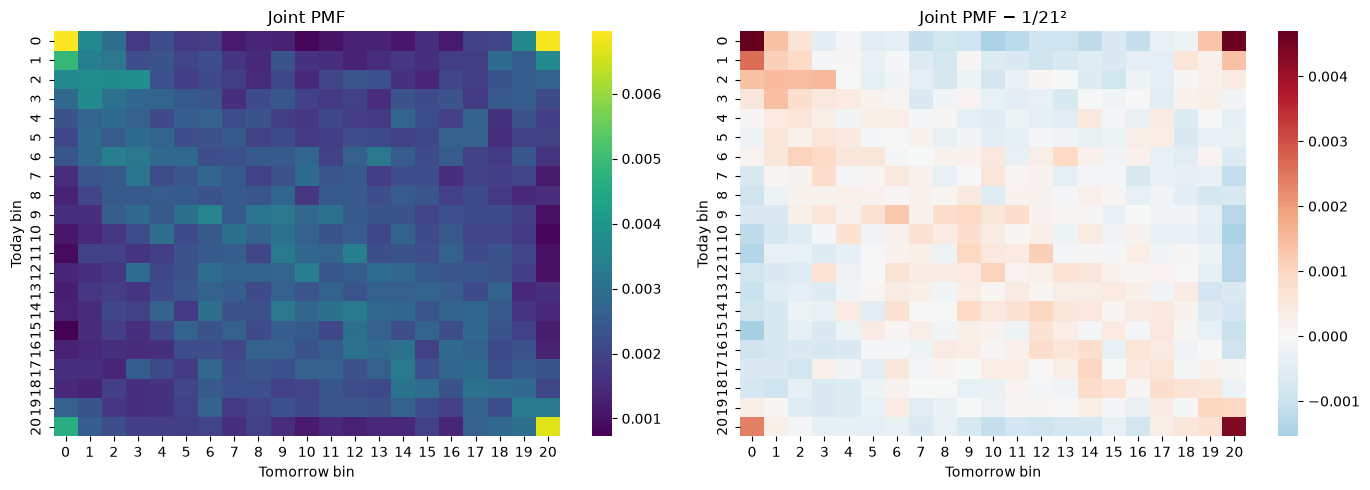

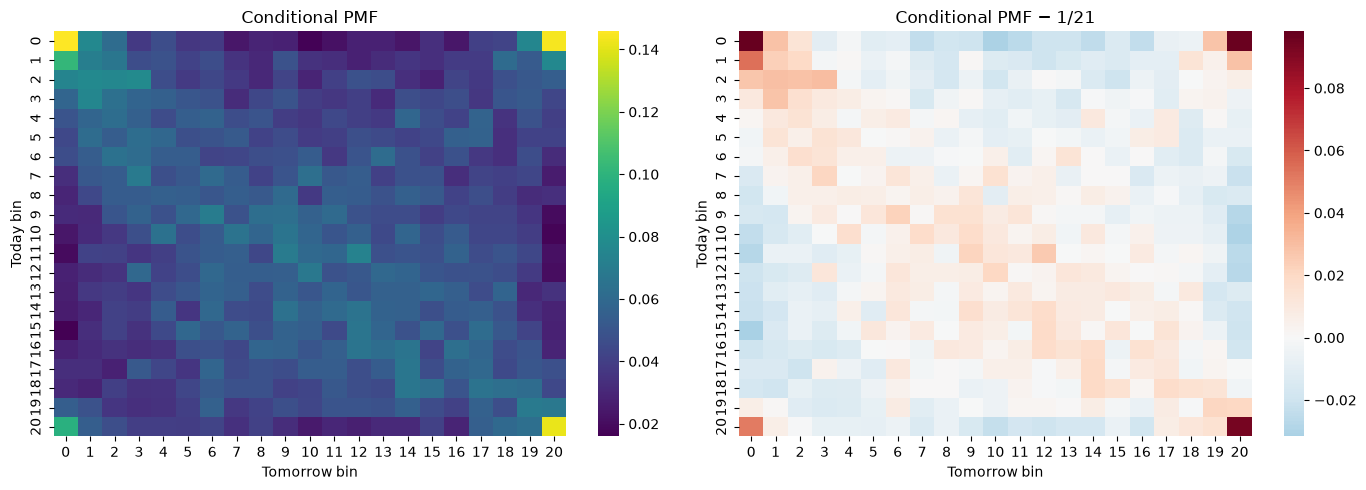

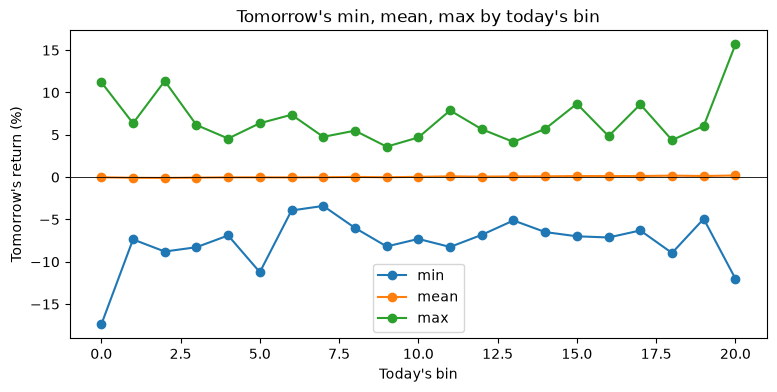

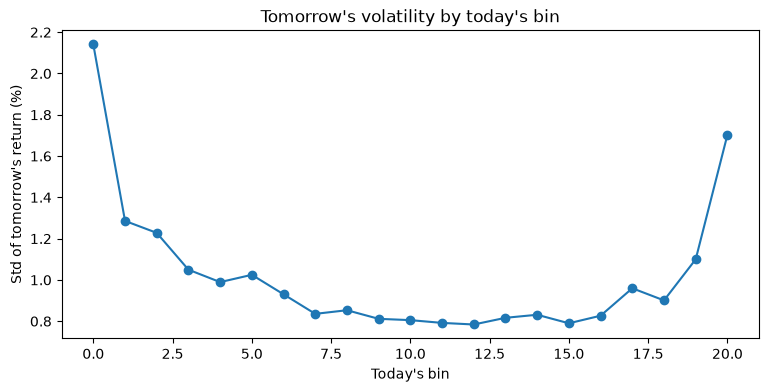

In [7]:
K = 21
df['y_t'] = pd.qcut(df['market_return_pct'], q=K, labels=False)   # 0..20
df['y_tp1'] = df['y_t'].shift(-1)
p21 = df.dropna(subset=['y_tp1']).copy()
p21['y_tp1'] = p21['y_tp1'].astype(int)

joint21 = pd.crosstab(p21['y_t'], p21['y_tp1'], normalize='all')
cond21 = joint21.div(joint21.sum(axis=1), axis=0)

# Joint PMF: raw and minus uniform
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(joint21, ax=axes[0], cmap='viridis')
axes[0].set(title='Joint PMF', xlabel='Tomorrow bin', ylabel='Today bin')
sns.heatmap(joint21 - 1/K**2, ax=axes[1], cmap='RdBu_r', center=0)
axes[1].set(title='Joint PMF − 1/21²', xlabel='Tomorrow bin', ylabel='Today bin')
fig.tight_layout(); plt.show()

# Conditional PMF: raw and minus uniform
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cond21, ax=axes[0], cmap='viridis')
axes[0].set(title='Conditional PMF', xlabel='Tomorrow bin', ylabel='Today bin')
sns.heatmap(cond21 - 1/K, ax=axes[1], cmap='RdBu_r', center=0)
axes[1].set(title='Conditional PMF − 1/21', xlabel='Tomorrow bin', ylabel='Today bin')
fig.tight_layout(); plt.show()

# Tomorrow's min / mean / max / std by today's bin
g = p21.groupby('y_t')['ret_tp1'].agg(['min', 'mean', 'max', 'std'])

fig, ax = plt.subplots(figsize=(9, 4))
g[['min', 'mean', 'max']].plot(ax=ax, marker='o')
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel="Today's bin", ylabel="Tomorrow's return (%)",
       title="Tomorrow's min, mean, max by today's bin")
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
g['std'].plot(ax=ax, marker='o')
ax.set(xlabel="Today's bin", ylabel="Std of tomorrow's return (%)",
       title="Tomorrow's volatility by today's bin")
plt.show()